In [16]:
import pandas as pd

df = pd.read_parquet("../data/processed/dataset.parquet")
standard = df[
    (df["battle_type"] == 1)
    & (df["gameplay_id"] == "ctf")
    & (~df["is_bot"])
    & (df["alive_at_90"])
    & (df["x"].notna())
]
standard = standard.copy()
standard["damage_rel"] = standard["damage"] / standard.groupby("arena_id")["damage"].transform("mean")
lake = standard[standard["map_name"] == "07_lakeville"]
lake.shape, lake["team"].value_counts()

((154, 23),
 team
 1    133
 2     21
 Name: count, dtype: int64)

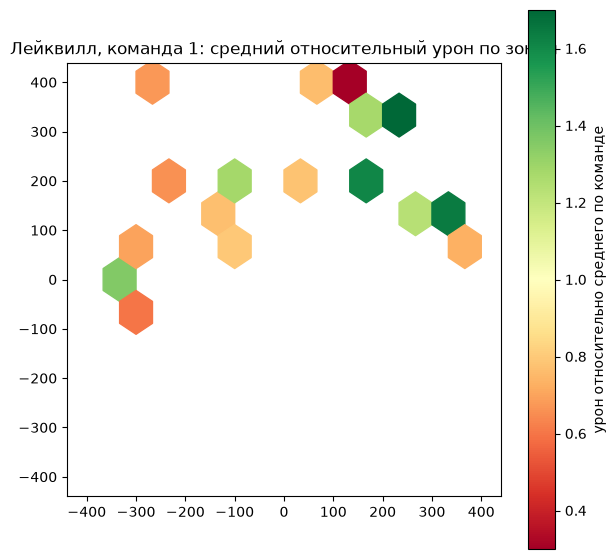

In [17]:
import numpy as np

team1 = lake[lake["team"] == 1]

fig, ax = plt.subplots(figsize=(7, 7))
hb = ax.hexbin(
    team1["x"], team1["z"], C=team1["damage_rel"],
    reduce_C_function=np.mean, gridsize=12, mincnt=3,
    extent=(-400, 400, -400, 400), cmap="RdYlGn", vmin=0.3, vmax=1.7,
)
fig.colorbar(hb, ax=ax, label="урон относительно среднего по команде")
ax.set_aspect("equal")
ax.set_title("Лейквилл, команда 1: средний относительный урон по зонам")
plt.show()

In [13]:
standard.groupby("team")["arena_id"].nunique()

team
1    148
2    149
Name: arena_id, dtype: int64

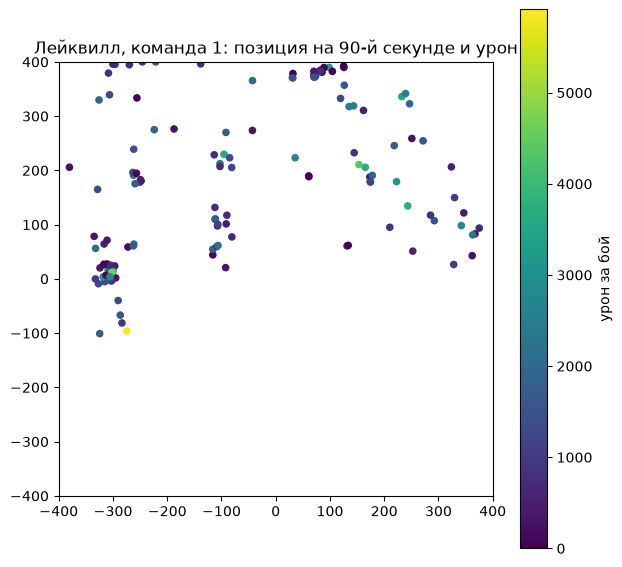

In [14]:
team1 = lake[lake["team"] == 1]

fig, ax = plt.subplots(figsize=(7, 7))
points = ax.scatter(team1["x"], team1["z"], c=team1["damage"], cmap="viridis", s=20)
fig.colorbar(points, ax=ax, label="урон за бой")
ax.set_aspect("equal")
ax.set_xlim(-400, 400)
ax.set_ylim(-400, 400)
ax.set_title("Лейквилл, команда 1: позиция на 90-й секунде и урон")
plt.show()

In [9]:
df["x"].isna().mean()

np.float64(0.0013062138458667662)

In [5]:
df.groupby(["battle_type", "gameplay_id"]).size()

battle_type  gameplay_id
1            ctf            4441
20           domination      826
43           comp7            77
44           ctf              15
dtype: int64

In [6]:
df[["is_bot", "is_recorder", "alive_at_90", "won"]].mean()

is_bot         0.004292
is_recorder    0.079679
alive_at_90    0.949804
won            0.737451
dtype: float64